# Live demo: building your first machine learning model
**From Report to System · SPE Sudan Section**

We'll predict house prices with the same pipeline we use for oil and gas data:

1. Define the problem → 2. Collect data → 3. Explore (EDA) → 4. Clean and split → 5. Train → 6. Evaluate → 7. Compare methods → 8. Use the model

*Run each cell with **Shift + Enter**.*

## Step 1 · Define the problem
**Question:** Can we predict a house's price from its area, number of bedrooms, age and distance to the city centre?

This is **supervised learning (regression)**: we have past examples with known prices, and we want to predict a number.

In [1]:
# Tools we need
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Large fonts so the room can read the charts
plt.rcParams.update({"font.size": 14, "figure.figsize": (9, 5)})

## Step 2 · Collect the data
We create a small **practice dataset** of 300 houses (made up, but realistic).
Like real field data, it contains a few **missing values** and some **data-entry errors**.

In [2]:
rng = np.random.default_rng(42)
n = 300

area      = rng.uniform(80, 400, n).round()        # m²
bedrooms  = rng.integers(1, 7, n)
age       = rng.integers(0, 40, n)                 # years
distance  = rng.uniform(1, 30, n).round(1)         # km to city centre

price = (20_000 + 900 * area + 8_000 * bedrooms
         - 600 * age - 3_000 * distance
         + rng.normal(0, 20_000, n)).clip(min=40_000).round(-2)   # USD

df = pd.DataFrame({"area_m2": area, "bedrooms": bedrooms, "age_years": age,
                   "distance_km": distance, "price_usd": price})

# Real data is never perfect: add missing values and typing errors
df.loc[rng.choice(n, 6, replace=False), "area_m2"] = np.nan
errors = rng.choice(n, 5, replace=False)
df.loc[errors, "price_usd"] = df.loc[errors, "price_usd"] * 10   # extra zero typed

df.head()

,area_m2,bedrooms,age_years,distance_km,price_usd
0,328.0,4,0,14.8,291100.0
1,220.0,5,1,23.1,187200.0
2,355.0,5,8,27.2,298700.0
3,303.0,1,35,21.9,193800.0
4,110.0,5,18,28.9,76000.0


## Step 3 · Explore the data (EDA)
Before any model: **look at the statistics, check for missing values, and plot the data.**

In [3]:
df.describe().round(0)

,area_m2,bedrooms,age_years,distance_km,price_usd
count,294.0,300.0,300.0,300.0,300.0
mean,234.0,4.0,20.0,15.0,233985.0
std,93.0,2.0,11.0,9.0,275831.0
min,82.0,1.0,0.0,1.0,40000.0
25%,150.0,2.0,11.0,8.0,132250.0
50%,232.0,4.0,20.0,16.0,203100.0
75%,319.0,5.0,28.0,23.0,275525.0
max,398.0,6.0,39.0,30.0,3457000.0


In [4]:
print("Missing values per column:")
df.isna().sum()

Missing values per column:


area_m2        6
bedrooms       0
age_years      0
distance_km    0
price_usd      0
dtype: int64

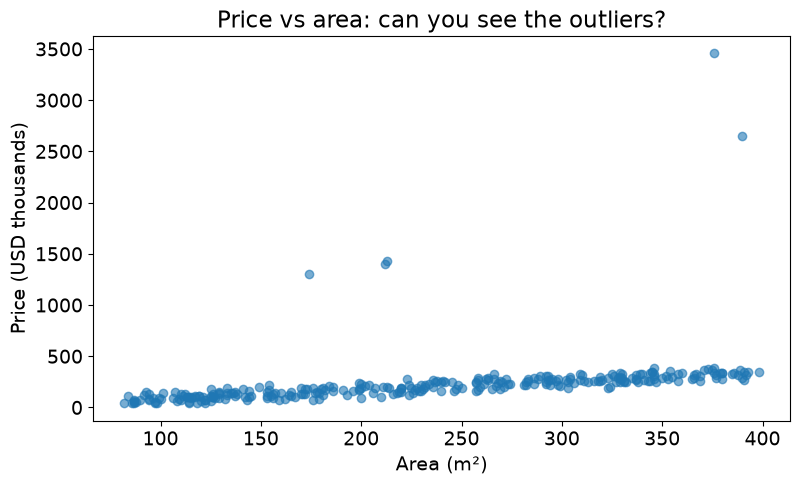

In [5]:
plt.scatter(df["area_m2"], df["price_usd"] / 1000, alpha=0.6)
plt.xlabel("Area (m²)")
plt.ylabel("Price (USD thousands)")
plt.title("Price vs area: can you see the outliers?")
plt.show()

## Step 4 · Clean the data and split it
- Remove rows with missing area
- Remove outliers (price far outside the normal range, using the IQR rule)
- Split into **training** data (to learn) and **test** data (to check, never seen during training)

Rows before: 300   after cleaning: 289


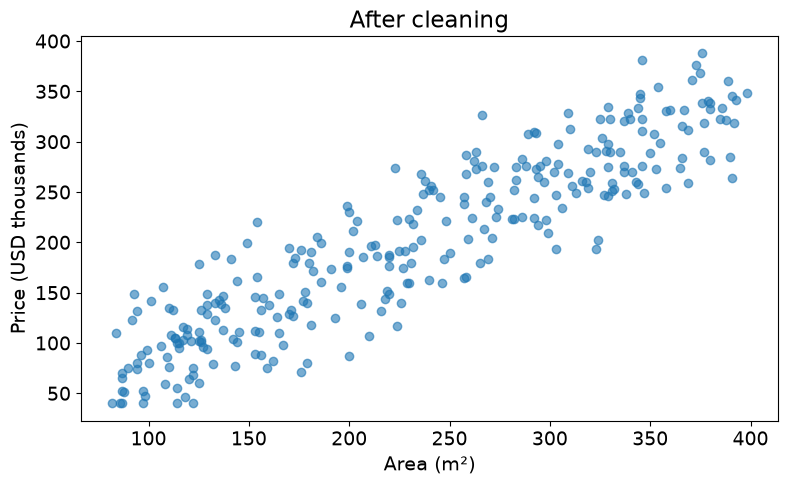

In [6]:
clean = df.dropna()

q1, q3 = clean["price_usd"].quantile([0.25, 0.75])
iqr = q3 - q1
clean = clean[clean["price_usd"].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)]

print(f"Rows before: {len(df)}   after cleaning: {len(clean)}")

plt.scatter(clean["area_m2"], clean["price_usd"] / 1000, alpha=0.6)
plt.xlabel("Area (m²)"); plt.ylabel("Price (USD thousands)")
plt.title("After cleaning")
plt.show()

In [7]:
X = clean[["area_m2", "bedrooms", "age_years", "distance_km"]]   # inputs (features)
y = clean["price_usd"]                                           # target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training houses: {len(X_train)}   Test houses: {len(X_test)}")

Training houses: 231   Test houses: 58


## Step 5 · Train the model
We start with the simplest model: **linear regression**.

In [8]:
model = LinearRegression()
model.fit(X_train, y_train)

pd.Series(model.coef_, index=X.columns).round(0).to_frame("USD per unit")

,USD per unit
area_m2,866.0
bedrooms,8732.0
age_years,-604.0
distance_km,-3141.0


The model has **learned the rules from the data**: what each extra m², bedroom, year of age or km adds to (or removes from) the price.

## Step 6 · Evaluate on houses the model has never seen
We compare with a **naive benchmark**: always guess the average price. A model is only useful if it beats this.

In [9]:
pred = model.predict(X_test)
naive = np.full(len(y_test), y_train.mean())

print(f"Naive benchmark  MAE: ${mean_absolute_error(y_test, naive):,.0f}")
print(f"Linear model     MAE: ${mean_absolute_error(y_test, pred):,.0f}   R²: {r2_score(y_test, pred):.2f}")

Naive benchmark  MAE: $83,336
Linear model     MAE: $14,796   R²: 0.95


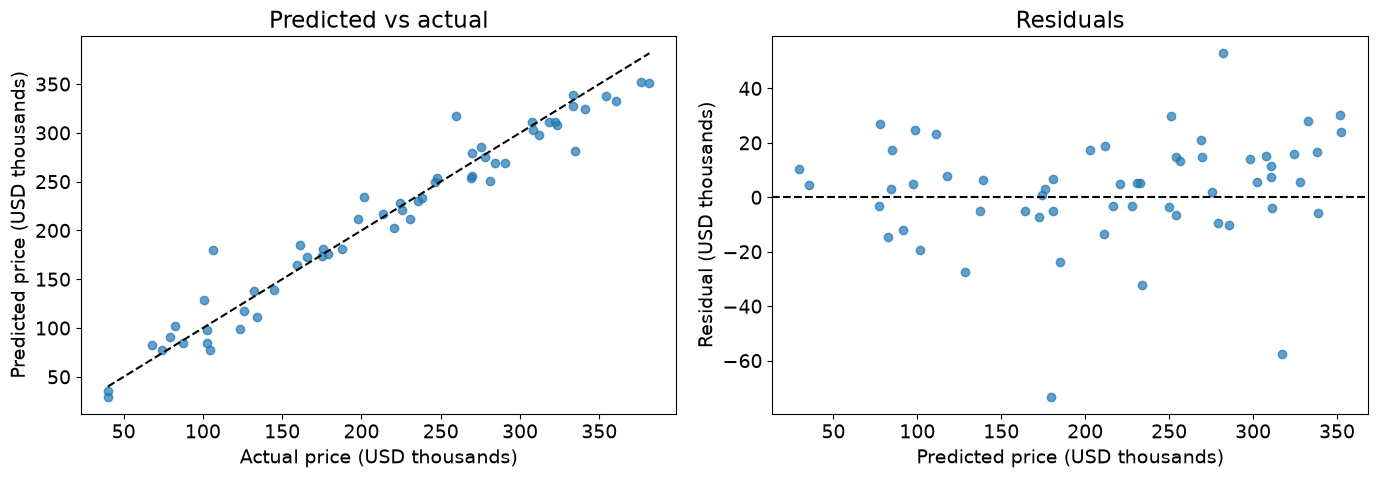

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(y_test / 1000, pred / 1000, alpha=0.7)
lims = [y_test.min() / 1000, y_test.max() / 1000]
ax[0].plot(lims, lims, "k--")
ax[0].set_xlabel("Actual price (USD thousands)"); ax[0].set_ylabel("Predicted price (USD thousands)")
ax[0].set_title("Predicted vs actual")

residuals = y_test - pred
ax[1].scatter(pred / 1000, residuals / 1000, alpha=0.7)
ax[1].axhline(0, color="k", linestyle="--")
ax[1].set_xlabel("Predicted price (USD thousands)"); ax[1].set_ylabel("Residual (USD thousands)")
ax[1].set_title("Residuals")
plt.tight_layout(); plt.show()

## Step 7 · Compare methods
Is a more complex model better? Let's try a **random forest** on the same data.

In [11]:
forest = RandomForestRegressor(n_estimators=200, random_state=42)
forest.fit(X_train, y_train)
pred_rf = forest.predict(X_test)

results = pd.DataFrame({
    "MAE (USD)": [mean_absolute_error(y_test, naive),
                  mean_absolute_error(y_test, pred),
                  mean_absolute_error(y_test, pred_rf)],
    "R²": [r2_score(y_test, naive), r2_score(y_test, pred), r2_score(y_test, pred_rf)],
}, index=["Naive benchmark", "Linear regression", "Random forest"])
results.round({"MAE (USD)": 0, "R²": 2})

,MAE (USD),R²
Naive benchmark,83336.0,-0.04
Linear regression,14796.0,0.95
Random forest,23271.0,0.91


More complex is **not always better**. Always compare, and choose the model that performs best on unseen data.

## Step 8 · Use the model
Change the numbers and run the cell again.

In [12]:
new_house = pd.DataFrame({"area_m2": [200], "bedrooms": [3],
                          "age_years": [10], "distance_km": [5]})

print(f"Predicted price: ${model.predict(new_house)[0]:,.0f}")

Predicted price: $205,373


## Back to oil and gas
The pipeline is exactly the same for our data:

| House price demo | Porosity–permeability |
|---|---|
| Inputs: area, bedrooms, age, distance | Inputs: porosity (and other logs) |
| Target: price | Target: permeability (log K) |
| Typing errors, missing values | Measurement errors, missing core data |
| Residuals: actual − predicted | Residuals: measured − predicted K |

**Same steps: define → collect → explore → clean → train → evaluate → compare → use.**